# Analysis - Late Deliveries

This notebook reads the saved model and `reports/` written by
`python -m latedeliveries.train`.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold

from latedeliveries.data import make_orders
from latedeliveries.evaluation import THRESHOLDS, order_cost, out_of_fold_probabilities
from latedeliveries.pipeline import RANDOM_STATE, split_orders

ROOT = Path("..")

orders = make_orders(n=3000, seed=7)
X_train, X_test, y_train, y_test = split_orders(orders)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

model = joblib.load(ROOT / "models" / "late_orders.joblib")
metrics = json.loads((ROOT / "reports" / "metrics.json").read_text())
threshold = metrics["threshold"]

## 1. How common are late orders?

In [2]:
late = orders["late"]
print(f"Late orders: {late.sum()} of {len(late)} ({late.mean():.1%})")
print(f"Train late rate {y_train.mean():.3f}, test late rate {y_test.mean():.3f}")

Late orders: 468 of 3000 (15.6%)
Train late rate 0.156, test late rate 0.156


→ About one order in six is late, so a model that always says "on time" is already
right about 84% of the time. Accuracy alone cannot judge this problem.

## 2. Model comparison (5-fold CV, training data only)

In [3]:
cv = pd.read_csv(ROOT / "reports" / "cv_results.csv").set_index("model")
cv.round(3)

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
model,,,,,,,,,,
DummyClassifier,0.844,0.001,0.000,0.000,0.000,0.000,0.000,0.000,0.500,0.000
LogisticRegression,0.860,0.010,0.638,0.093,0.239,0.034,0.348,0.049,0.806,0.033
RandomForest,0.861,0.007,0.678,0.089,0.211,0.024,0.321,0.033,0.777,0.028
BalancedDecisionTree,0.789,0.016,0.325,0.045,0.327,0.066,0.325,0.050,0.601,0.031


→ The dummy baseline reaches 0.844 accuracy with recall 0: it never flags a late order.  
→ LogisticRegression has the highest ROC-AUC (0.806), so it ranks late orders best, and was chosen for tuning.

## 3. Cost against threshold (training data only)

Cost = $4 for every flagged order + $15 for every late order not flagged.
Each training order gets a probability from a model that never saw it (out-of-fold), and the threshold with the lowest total cost is chosen. The test set plays no part.

In [4]:
probability = out_of_fold_probabilities(clone(model), X_train, y_train, folds)
costs = pd.Series(index=THRESHOLDS, dtype=int)
for t in THRESHOLDS:
    costs[t] = order_cost(y_train, probability >= t)
nobody = order_cost(y_train, [False] * len(y_train))
print(f"Chosen threshold {threshold}: training cost ${costs[threshold]:,}")
print(f"Flag nobody on the training rows: ${nobody:,}")

Chosen threshold 0.65: training cost $4,063.0
Flag nobody on the training rows: $5,265


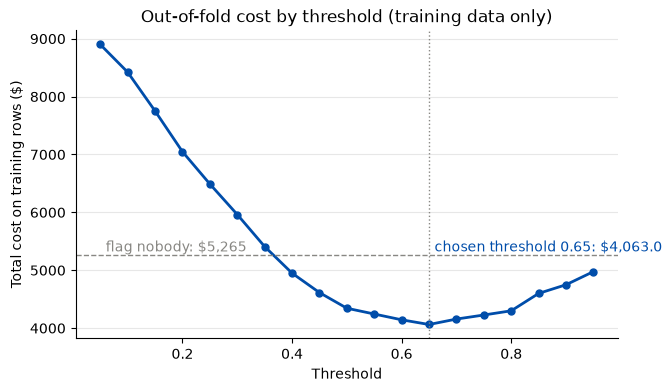

In [5]:
BLUE, GREY = "#004daa", "#888783"

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(costs.index, costs.values, color=BLUE, linewidth=2, marker="o", markersize=5)
ax.axhline(nobody, color=GREY, linewidth=1, linestyle="--")
ax.text(0.06, nobody + 60, f"flag nobody: ${nobody:,}", color=GREY)
ax.axvline(threshold, color=GREY, linewidth=1, linestyle=":")
ax.text(
    threshold + 0.01,
    nobody + 60,
    f"chosen threshold {threshold}: ${costs[threshold]:,}",
    color=BLUE,
)
ax.set(
    xlabel="Threshold",
    ylabel="Total cost on training rows ($)",
    title="Out-of-fold cost by threshold (training data only)",
)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.show()

→ Low thresholds flag too many orders and pay for vouchers, high thresholds miss late orders. The lowest cost is at 0.65. It looks high because `class_weight="balanced"` pushes predicted probabilities up, so 0.65 is not a 65% chance of being late.

## 4. Test set - Confusion Matrix

The final model was fitted on the whole training set and scored on the test set once
in the final run of `train.py`. These numbers are read from `reports/metrics.json`,
not recomputed.

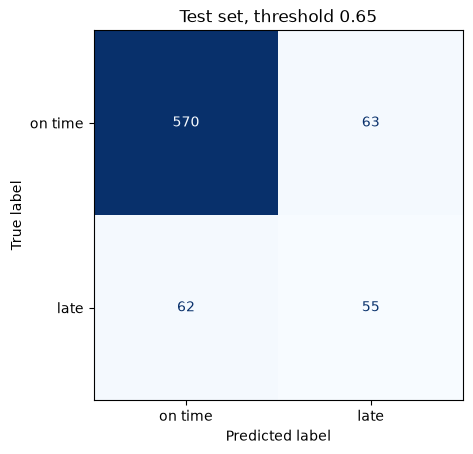

precision 0.466, recall 0.47, f1 0.468, roc_auc 0.766


In [6]:
test = metrics["test"]
ConfusionMatrixDisplay(
    np.array(test["confusion_matrix"]), display_labels=["on time", "late"]
).plot(cmap="Blues", colorbar=False)
plt.title(f"Test set, threshold {threshold}")
plt.show()
print(
    f"precision {test['precision']}, "
    f"recall {test['recall']}, "
    f"f1 {test['f1']}, "
    f"roc_auc {test['roc_auc']}"
)

## 5. Cost of the three policies

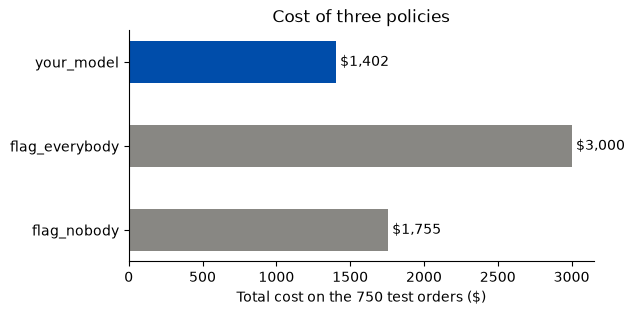

Saving against flagging nobody: $353 (20%)


In [7]:
policy = pd.Series(metrics["costs"])
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(policy.index, policy.values, color=[GREY, GREY, BLUE], height=0.5)
for i, value in enumerate(policy.values):
    ax.text(value + 30, i, f"${value:,}", va="center")
ax.set(xlabel=f"Total cost on the {len(y_test)} test orders ($)")
ax.set_title("Cost of three policies")
ax.spines[["top", "right"]].set_visible(False)
plt.show()
saving = policy["flag_nobody"] - policy["your_model"]
print(
    f"Saving against flagging nobody: ${saving} ({saving / policy['flag_nobody']:.0%})"
)

→ Our model costs $1,402 on the 750 test orders, against $1,755 for flagging nobody (the company's current policy) and $3,000 for flagging everybody: a saving of $353 (20%).

→ On the training rows (out-of-fold), the same threshold saved 23% against flagging
nobody ($4,063 vs $5,265). The test saving (20%) is close to that, so it is not a
lucky test set.

## 6. Recommendation

**Would we use this model?**  
Yes, for the voucher decision. On 750 unseen test orders it cost $1,402, against $1,755 for flagging nobody and $3,000 for flagging everybody: a saving of $353 (20%), close to the 23% seen out-of-fold on the training rows.

**Why this threshold?**  
Every flagged order costs $4, late or not, and every late order
we fail to flag costs $15. For each threshold from 0.05 to 0.95 in steps of 0.05, we
counted the flagged orders and the missed late orders in the training rows
(out-of-fold), and priced them at $4 and $15. 0.65 gave the lowest total ($4,063).

**What did we exclude and why?**  
`customer_rating` is given after delivery, so it is not known when the order is placed.
`order_id` is only a label.

**One limitation.**  
In this data `prep_minutes` is the time the kitchen actually took, but when an order is placed the restaurant can only enter an estimate, and the real
time may be shorter or longer depending on how cooking goes. The model learned from
exact values, so in real use it will likely do a little worse than the test result.
